# Who survived the Titanic?

Machine learning from scratch, episode 1.

In [1]:
import pandas as pd
from sklearn.datasets import fetch_openml

df = fetch_openml("titanic", version=1, as_frame=True,
                  parser="liac-arff").frame
df.shape

(1309, 14)

In [2]:
df[["name", "sex", "age", "pclass", "fare", "survived"]].head()

,name,sex,age,pclass,fare,survived
0,"Allen, Miss. Elisabeth Walton",female,29.0000,1.0,211.3375,1
1,"Allison, Master. Hudson Trevor",male,0.9167,1.0,151.5500,1
2,"Allison, Miss. Helen Loraine",female,2.0000,1.0,151.5500,0
3,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1.0,151.5500,0
4,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1.0,151.5500,0


In [3]:
df.iloc[0]

pclass                                 1.0
survived                                 1
name         Allen, Miss. Elisabeth Walton
sex                                 female
age                                   29.0
sibsp                                  0.0
parch                                  0.0
ticket                               24160
fare                              211.3375
cabin                                   B5
embarked                                 S
boat                                     2
body                                   NaN
home.dest                     St Louis, MO
Name: 0, dtype: object

In [4]:
df.isna().sum()

pclass          0
survived        0
name            0
sex             0
age           263
sibsp           0
parch           0
ticket          0
fare            1
cabin        1014
embarked        2
boat          823
body         1188
home.dest     564
dtype: int64

In [5]:
df["survived"].value_counts()

survived
0    809
1    500
Name: count, dtype: int64

The share who survived: $p = \frac{500}{1309} \approx 0.38$

In [6]:
df["survived"] = df["survived"].astype(int)
df["pclass"] = df["pclass"].astype(int)
df.groupby("sex")["survived"].mean()

sex
female    0.727468
male      0.190985
Name: survived, dtype: float64

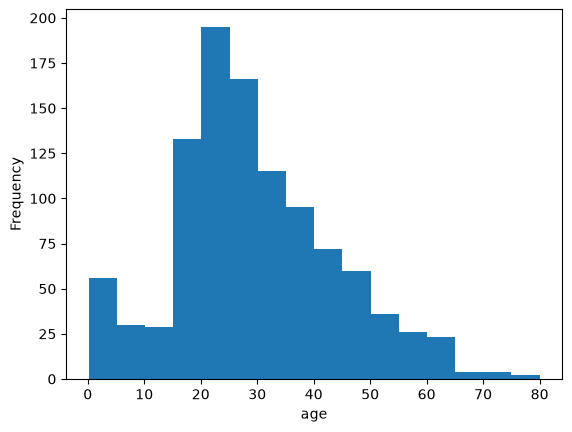

In [7]:
df["age"].plot.hist(bins=16, xlabel="age");

In [8]:
ages = pd.cut(df["age"], [0, 10, 20, 40, 60, 80])
df.groupby(ages)["survived"].mean()

age
(0, 10]     0.581395
(10, 20]    0.395062
(20, 40]    0.390543
(40, 60]    0.422680
(60, 80]    0.242424
Name: survived, dtype: float64

In [9]:
df.groupby("pclass")["survived"].mean()

pclass
1    0.619195
2    0.429603
3    0.255289
Name: survived, dtype: float64

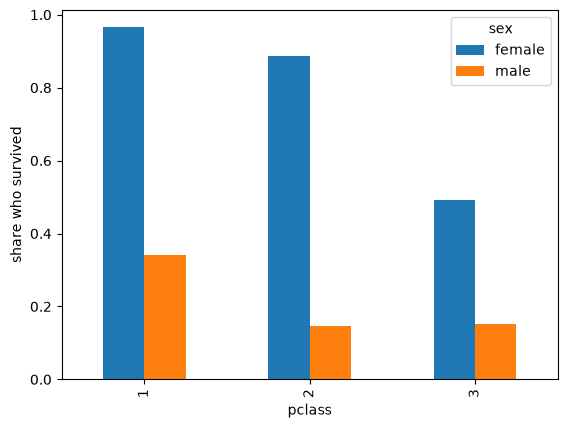

In [10]:
chart = df.groupby(["pclass", "sex"])["survived"].mean().unstack()
chart.plot.bar(ylabel="share who survived");

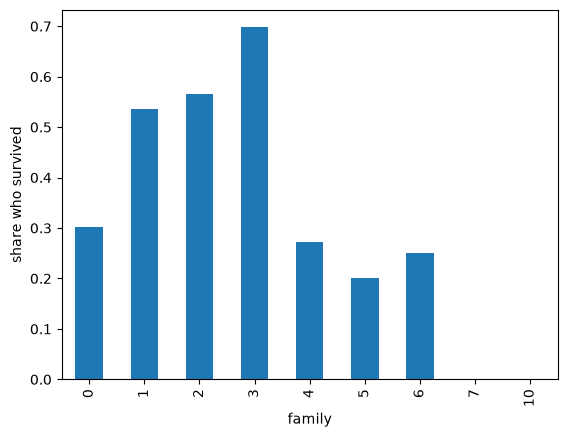

In [11]:
df["family"] = (df["sibsp"] + df["parch"]).astype(int)
df.groupby("family")["survived"].mean().plot.bar(ylabel="share who survived");

In [12]:
X = pd.DataFrame({
    "female": (df["sex"] == "female").astype(int),
    "pclass": df["pclass"],
    "age": df["age"].fillna(df["age"].median()),
    "fare": df["fare"].fillna(df["fare"].median()),
    "family": df["family"],
})
y = df["survived"]
X.head()

,female,pclass,age,fare,family
0,1,1,29.0000,211.3375,0
1,0,1,0.9167,151.5500,3
2,1,1,2.0000,151.5500,3
3,0,1,30.0000,151.5500,3
4,1,1,25.0000,151.5500,3


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0)
len(X_train), len(X_test)

(981, 328)

Gini impurity: $G = 1 - p^2 - (1 - p)^2$

In [14]:
def gini(answers):
    p = answers.mean()
    return 1 - p**2 - (1 - p)**2

women = X_train["female"] == 1
print(round(gini(y_train), 3))
print(round(gini(y_train[women]), 3), round(gini(y_train[~women]), 3))

0.475
0.392 0.31


In [15]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=3, random_state=0)
tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in 

In [16]:
guess = tree.predict(X_test)
pd.DataFrame({"guess": guess, "truth": y_test}).head()

,guess,truth
1139,0,0
533,1,1
459,0,0
1150,0,0
393,0,0


In [17]:
tree.score(X_test, y_test)

0.8140243902439024

$\text{accuracy} = \dfrac{\text{right answers}}{\text{all answers}}$

In [18]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_test, guess)

array([[182,  26],
       [ 35,  85]])

In [19]:
everyone_died = (y_test == 0).mean()
women_survive = (X_test["female"] == y_test).mean()
print(everyone_died.round(3), women_survive.round(3))

0.634 0.777


In [20]:
from sklearn.tree import export_text

print(export_text(tree, feature_names=list(X.columns)))

|--- female <= 0.50
|   |--- age <= 13.50
|   |   |--- family <= 3.50
|   |   |   |--- class: 1
|   |   |--- family >  3.50
|   |   |   |--- class: 0
|   |--- age >  13.50
|   |   |--- pclass <= 1.50
|   |   |   |--- class: 0
|   |   |--- pclass >  1.50
|   |   |   |--- class: 0
|--- female >  0.50
|   |--- pclass <= 2.50
|   |   |--- fare <= 31.68
|   |   |   |--- class: 1
|   |   |--- fare >  31.68
|   |   |   |--- class: 1
|   |--- pclass >  2.50
|   |   |--- fare <= 23.35
|   |   |   |--- class: 1
|   |   |--- fare >  23.35
|   |   |   |--- class: 0



In [21]:
pd.Series(tree.feature_importances_, index=X.columns).round(2)

female    0.66
pclass    0.19
age       0.04
fare      0.06
family    0.05
dtype: float64

In [22]:
deep = DecisionTreeClassifier(random_state=0)
deep.fit(X_train, y_train)
deep.score(X_train, y_train), deep.score(X_test, y_test)

(0.9714576962283384, 0.7621951219512195)

In [23]:
for depth in range(1, 11):
    t = DecisionTreeClassifier(max_depth=depth, random_state=0)
    t.fit(X_train, y_train)
    print(depth, round(t.score(X_train, y_train), 3),
          round(t.score(X_test, y_test), 3))

1 0.781 0.777
2 0.782 0.787
3 0.817 0.814
4 0.822 0.802
5 0.834 0.808
6 0.843 0.799
7 0.859 0.78
8 0.871 0.784
9 0.884 0.774
10 0.896 0.777


In [24]:
people = pd.DataFrame({"female": [0, 1], "pclass": [3, 1], "age": [20, 17],
                       "fare": [7.0, 100.0], "family": [0, 1]},
                      index=["Jack", "Rose"])
tree.predict(people)

array([0, 1])

In [25]:
tree.predict_proba(people).round(2)

array([[0.87, 0.13],
       [0.03, 0.97]])